In [129]:
# Author: Till Zemann
# License: MIT License
# import sys
# sys.path.append("..")
from __future__ import annotations

import os

import matplotlib.pyplot as plt
import numpy as np
import torch
import pickle as pkl
print(torch.__version__)
from net.a2c import A2C
from net.dale_util import RL_Hidden_Buffer
from rl.rl_fitting import run_hmm_metrics

1.12.0


In [22]:
kwargs = {
    'simple_type': 'rnn',
    'ei_type': 'eisep',
    'actor_lr': 0.001,
    'critic_lr': 0.005,
}
network_names = ['critic', 'actor']
n_seed = 5
validation_names = ['train', 'test']
configurations = ['eisep_all', 'simple']
ll_avg = np.zeros((len(network_names), len(validation_names), len(configurations), n_seed))
switch_rate = np.zeros((len(network_names), len(validation_names), len(configurations), n_seed))
stickiness = np.zeros((len(network_names), len(configurations), n_seed))
entropy = np.zeros((len(network_names), len(configurations), n_seed))
nmi = np.zeros((len(network_names), len(validation_names), len(configurations), n_seed))
for i, network_name in enumerate(network_names):
    for j, configuration in enumerate(configurations):
        print(network_name, configuration)
        for k in range(n_seed):
            kwargs['network_name'] = network_name
            kwargs['configuration'] = configuration
            kwargs['seed'] = k
            # if configuration == 'eisep_all':
            #     kwargs['actor_lr'] = 0.003
            #     kwargs['critic_lr'] = 0.005
            # elif configuration == 'simple':
            #     kwargs['actor_lr'] = 0.0003
            #     kwargs['critic_lr'] = 0.0015
            train_ll_avg, test_ll_avg, train_switch_rate, test_switch_rate, \
                        stickiness_single, entropy_single, train_nmi, test_nmi = run_hmm_metrics(**kwargs)
            ll_avg[i, 0, j, k] = train_ll_avg
            ll_avg[i, 1, j, k] = test_ll_avg
            switch_rate[i, 0, j, k] = train_switch_rate
            switch_rate[i, 1, j, k] = test_switch_rate
            stickiness[i, j, k] = stickiness_single
            entropy[i, j, k] = entropy_single
            nmi[i, 0, j, k] = train_nmi
            nmi[i, 1, j, k] = test_nmi

output = {
    'll_avg': ll_avg,
    'switch_rate': switch_rate,
    'stickiness': stickiness,
    'entropy': entropy,
    'nmi': nmi,
}
with open('./rl/hmm_metrics_rl.pkl', 'wb') as f:
    pkl.dump(output, f)


critic eisep_all
./rl/result/lunarlander/simple_rnn_ei_eisep/critic_0.005_actor_0.001/eisep_all_buffer0.pkl size: 9963
./rl/result/lunarlander/simple_rnn_ei_eisep/critic_0.005_actor_0.001/eisep_all_buffer1.pkl size: 8035
./rl/result/lunarlander/simple_rnn_ei_eisep/critic_0.005_actor_0.001/eisep_all_buffer2.pkl size: 8949
./rl/result/lunarlander/simple_rnn_ei_eisep/critic_0.005_actor_0.001/eisep_all_buffer3.pkl size: 10000
./rl/result/lunarlander/simple_rnn_ei_eisep/critic_0.005_actor_0.001/eisep_all_buffer4.pkl size: 5794
critic simple
./rl/result/lunarlander/simple_rnn_ei_eisep/critic_0.005_actor_0.001/simple_buffer0.pkl size: 10000
./rl/result/lunarlander/simple_rnn_ei_eisep/critic_0.005_actor_0.001/simple_buffer1.pkl size: 9505
./rl/result/lunarlander/simple_rnn_ei_eisep/critic_0.005_actor_0.001/simple_buffer2.pkl size: 10000
./rl/result/lunarlander/simple_rnn_ei_eisep/critic_0.005_actor_0.001/simple_buffer3.pkl size: 10000
./rl/result/lunarlander/simple_rnn_ei_eisep/critic_0.005_ac

In [23]:
print(ll_avg[0,1,1])

[ 334.33951517  136.72628414  -36.21744189 -176.87529249  171.08983276]


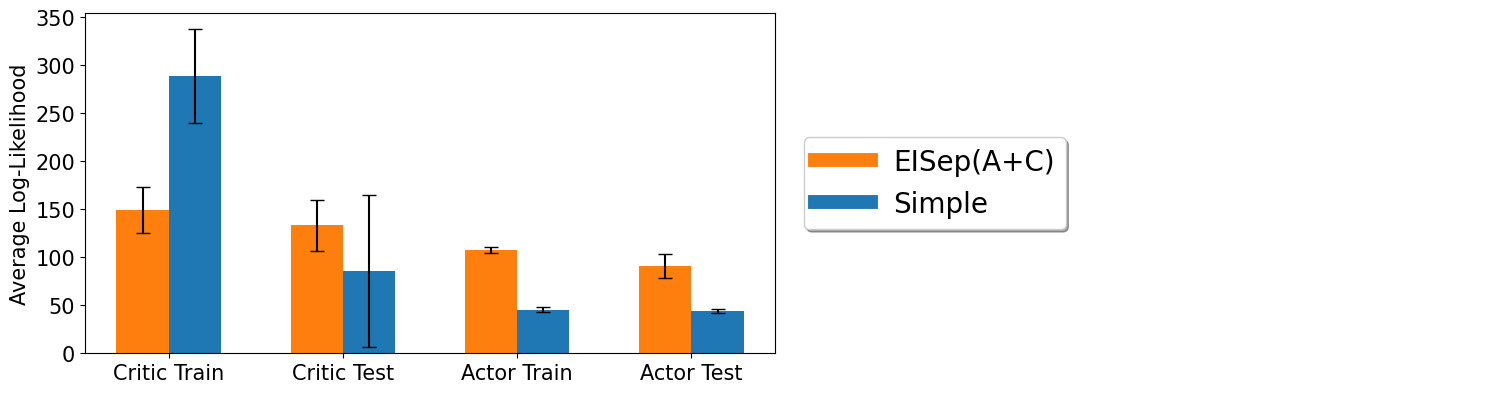

In [45]:
mean_avg = ll_avg.mean(axis=-1)
ste_avg = ll_avg.std(axis=-1)/np.sqrt(n_seed)
# Plotting
fontsize = 15
fig, ax = plt.subplots(1,2, figsize=(15,4))
network_name_titles = ['Critic', 'Actor']
configuration_titles = ['EISep(A+C)', 'Simple']
validation_name_titles = ['Train', 'Test']
colors = ['C1', 'C0']
configuration_offset = [0.2, 0.8]
lines = [None] * len(configurations)
metric_name = 'LL_Avg'
x_ticks = np.arange(len(network_names)*len(validation_name_titles))*2 + 0.5
x_ticklabels = ['Critic Train', 'Critic Test', 'Actor Train', 'Actor Test']
for j, network_name in enumerate(network_names):
    for k, validation_name in enumerate(validation_name_titles):
        for l, configuration in enumerate(configuration_titles):
            mean_data = mean_avg[j, k, l]
            ste_data = ste_avg[j, k, l]
            position = j*4 + k*2 + configuration_offset[l]
            lines[l] = ax[0].bar(position, mean_data, yerr=ste_data, color=colors[l], width=0.6, capsize=5)
ax[0].set_xticks(x_ticks)
ax[0].set_xticklabels(x_ticklabels)
ax[0].set_ylabel('Average Log-Likelihood', fontsize=fontsize)
# ax[0].set_title(metric_name, fontsize=fontsize)
ax[0].tick_params(labelsize=fontsize)
ax[1].plot(0,0, color='C1', label='EISep(A+C)', linewidth=10)
ax[1].plot(0,0, color='C0', label='Simple', linewidth=10)
ax[1].legend(fontsize=fontsize+5, loc='center left', framealpha=1, shadow=True, markerscale=1)
ax[1].axis('off')
plt.tight_layout()
plt.savefig('./rl/hmm_ll_avg_rl.png', dpi=400)

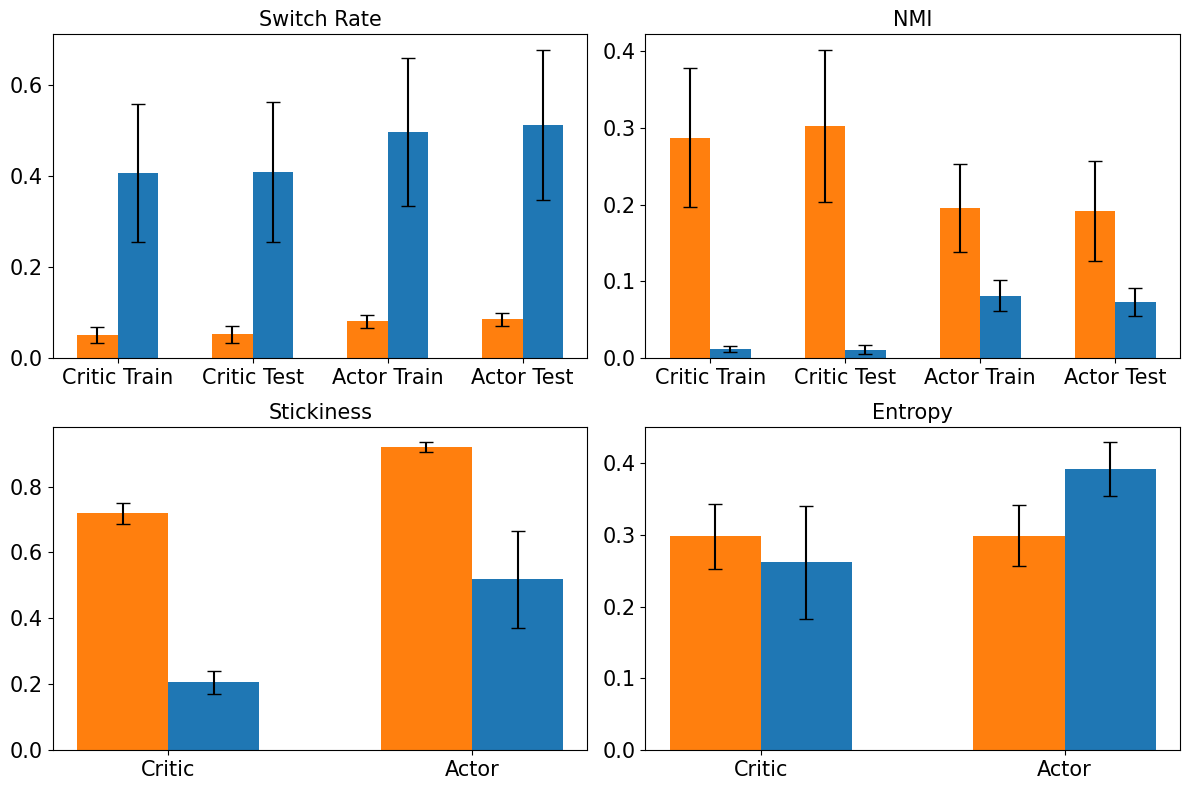

In [44]:
all_metrics = [switch_rate, nmi, stickiness, entropy]
mean_metrics = [np.mean(metric, axis=-1) for metric in all_metrics]
ste_metrics = [np.std(metric, axis=-1)/np.sqrt(n_seed) for metric in all_metrics]
# Plotting
fontsize = 15 
fig, ax = plt.subplots(2,2, figsize=(12,8))
ax = ax.flatten()
network_name_titles = ['Critic', 'Actor']
configuration_titles = ['EISep(A+C)', 'Simple']
validation_name_titles = ['Train', 'Test']
colors = ['C1', 'C0']
configuration_offset = [0.2, 0.8]
lines = [None] * len(configurations)
for i, metric_name in enumerate(['Switch Rate', 'NMI', 'Stickiness', 'Entropy']):
    if metric_name in ['Stickiness', 'Entropy']:
        x_ticks = np.arange(len(network_names))*2 + 0.5
        x_ticklabels = ['Critic', 'Actor']
        for j, network_name in enumerate(network_name_titles):
            for k, configuration in enumerate(configuration_titles):
                mean_data = mean_metrics[i][j, k]
                ste_data = ste_metrics[i][j, k]
                position = j*2 + configuration_offset[k]
                lines[k] = ax[i].bar(position, mean_data, yerr=ste_data, color=colors[k], width=0.6, capsize=5)
    else:
        x_ticks = np.arange(len(network_names)*len(validation_name_titles))*2 + 0.5
        x_ticklabels = ['Critic Train', 'Critic Test', 'Actor Train', 'Actor Test']
        for j, network_name in enumerate(network_names):
            for k, validation_name in enumerate(validation_name_titles):
                for l, configuration in enumerate(configuration_titles):
                    mean_data = mean_metrics[i][j, k, l]
                    ste_data = ste_metrics[i][j, k, l]
                    position = j*4 + k*2 + configuration_offset[l]
                    lines[l] = ax[i].bar(position, mean_data, yerr=ste_data, color=colors[l], width=0.6, capsize=5)
    ax[i].set_xticks(x_ticks)
    ax[i].set_xticklabels(x_ticklabels)
    ax[i].set_title(metric_name, fontsize=fontsize)
    ax[i].tick_params(labelsize=fontsize)
    # ax[i].legend(lines, configuration_titles)
# ax[0].set_ylim(-500, 800)
# ax[1].set_ylim(0,0.5)
plt.tight_layout()
plt.savefig('./rl/hmm_metrics_rl.png')

In [204]:
buffer = RL_Hidden_Buffer(10000)
simple_type = 'rnn'
ei_type = 'eisep'
configuration = 'eisep_all'
actor_lr = 0.001
critic_lr = 0.005

info_path = f'./rl/result/lunarlander/simple_{simple_type}_ei_{ei_type}/critic_{critic_lr}_actor_{actor_lr}/{configuration}.pkl'

buffer_path = info_path.replace('.pkl', '_buffer0.pkl')
buffer.load(buffer_path)
print(buffer.state.shape)
print(buffer.ptr, buffer.n_h)
# print(buffer.episode_rewards.mean())
network_name = 'actor'


./rl/result/lunarlander/simple_rnn_ei_eisep/critic_0.005_actor_0.001/eisep_all_buffer0.pkl size: 9963
(100000, 8)
9963 2


(9963, 4)
(9963, 12) (100000, 2, 64)
(9963, 64)
x: min -0.58, max 0.41,           mean -0.16, std 0.24
y: min 0.07, max 1.50,           mean 0.76, std 0.32
vx: min -0.79, max 0.51,           mean -0.04, std 0.14
vy: min -0.53, max 0.44,           mean -0.10, std 0.09
a: min -0.61, max 0.16,           mean -0.02, std 0.07
va: min -0.88, max 0.34,           mean -0.00, std 0.12


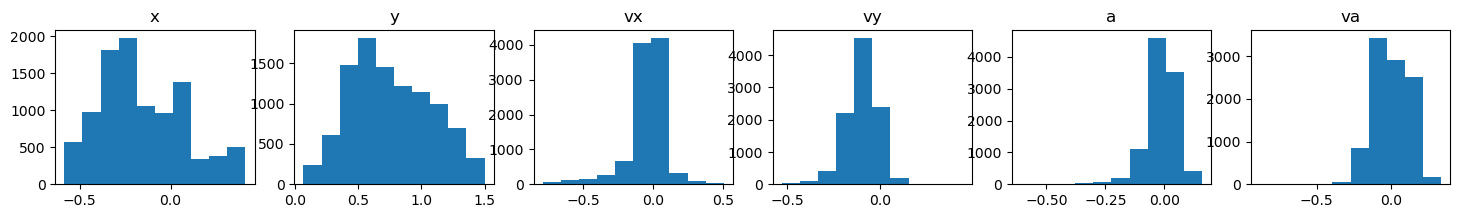

In [205]:
n_action = int(buffer.action.max()+1)
feature_dim = buffer.state.shape[-1] + n_action
buffer_state = buffer.state[:buffer.ptr]
buffer_action = buffer.action[:buffer.ptr]
buffer_done = buffer.done[:buffer.ptr]
buffer_action_onehot = np.eye(n_action)[buffer_action.astype(np.int64).squeeze(-1)]
print(buffer_action_onehot.shape)
features = np.concatenate([buffer_state, buffer_action_onehot], axis=-1)
print(features.shape, buffer.hidden_state.shape)
if network_name == 'critic':
    buffer_hidden = buffer.hidden_state[:buffer.ptr, 0]
elif network_name == 'actor':
    buffer_hidden = buffer.hidden_state[:buffer.ptr, 1]
print(buffer_hidden.shape)
### up is positive y velocity
fig, ax = plt.subplots(1,6, figsize=(18,2))
tick_names = ['x', 'y', 'vx', 'vy', 'a', 'va', 'lc', 'rc']
for i in range(6):
    ax[i].hist(buffer_state[:,i])
    print(f'{tick_names[i]}: min {buffer_state[:,i].min():.2f}, max {buffer_state[:,i].max():.2f}, \
          mean {buffer_state[:,i].mean():.2f}, std {buffer_state[:,i].std():.2f}')
    ax[i].set_title(tick_names[i])
plt.show()

./rl/output/lunarlander/simple_rnn_ei_eisep/critic_0.005_actor_0.001/eisep_all_hidden_activity_actor.png


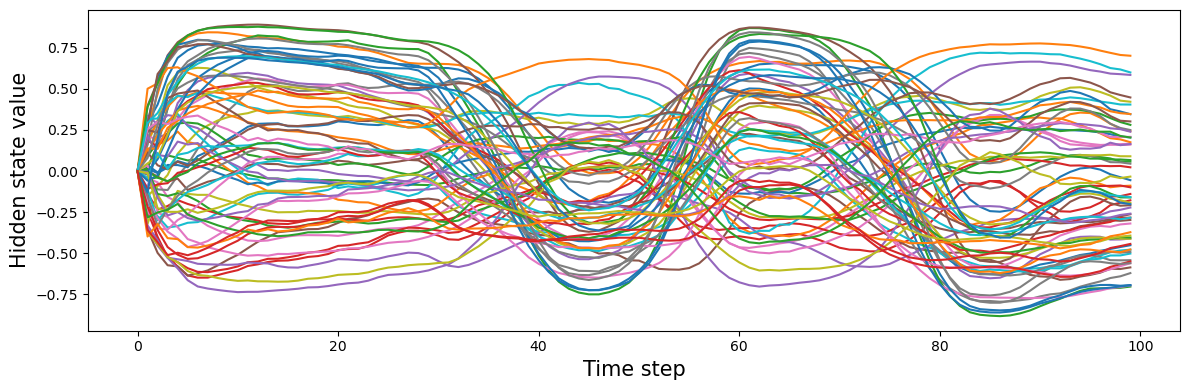

In [206]:
fig, ax = plt.subplots(1,1, figsize=(12,4))  
fontsize = 15 
for i in range(buffer_hidden.shape[1]):
    ax.plot(buffer_hidden[:100, i], label=f'unit {i}')
    # print(buffer_hidden[:50,i])
# ax.set_title(f'Hidden states of {network_name}', fontsize=fontsize)
ax.set_xlabel('Time step', fontsize=fontsize)
ax.set_ylabel('Hidden state value', fontsize=fontsize)
# ax.legend()
plt.tight_layout()
# plt.show()
path = f'./rl/output/lunarlander/simple_{simple_type}_ei_{ei_type}/critic_{critic_lr}_actor_{actor_lr}/{configuration}_hidden_activity_{network_name}.png'
os.makedirs(os.path.dirname(path), exist_ok=True)
plt.savefig(path, dpi=400)
print(path)

In [207]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from hmmlearn import hmm

def fit_hmm_gaussian(Z, done, n_components=8, cov_type="full", n_iter=200, seed=0):
    """
    Z: [T, r] latent features (mode coefficients / PCA of hidden)
    done: [T] bool/int, 1 at terminal steps (episode boundary)
    """
    Z = np.asarray(Z)
    done = np.asarray(done).reshape(-1).astype(bool)

    # Build lengths: split at done==1
    ends = np.where(done)[0]
    # Assume done marks the last step of an episode
    lengths = []
    start = 0
    for e in ends:
        L = (e - start + 1)
        if L > 1:
            lengths.append(L)
        start = e + 1
    if start < len(done):  # trailing partial episode
        lengths.append(len(done) - start)

    # Scale features
    scaler = StandardScaler()
    Zs = scaler.fit_transform(Z)

    model = hmm.GaussianHMM(
        n_components=n_components,
        covariance_type=cov_type,   # "full" or "diag"
        n_iter=n_iter,
        random_state=seed,
        verbose=False
    )

    model.fit(Zs, lengths=lengths)

    # Viterbi labels for all timesteps
    labels = model.predict(Zs, lengths=lengths)  # [T]
    post = model.predict_proba(Zs, lengths=lengths)  # [T, K], optional

    return labels, post, model, scaler, lengths
n_components = 5
hmm_labels, hmm_post, hmm_model, hmm_scaler, hmm_lengths = fit_hmm_gaussian(
    buffer_hidden,
    buffer_done,
    n_components=n_components,
    cov_type="full",
    n_iter=200,
    seed=0
)

6
HMM labels shape: (9963,) (9963, 5) 20
[500, 463, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500]
[1 1 1 1 1 1 1 1 1 1 0 1 0 1 1 1 1 1 1 0 1 1 1 1 1 1 0 0 0 2 2 2 2 1 2 2 2
 2 1 1 0 1 0 1 0 1 0 0 1 0 2 2 2 2 2 2 2 2 2 2 0 1 0 1 0 0 0 0 0 1 1 0 2 2
 2 2 2 2 2 2 2 2 2 1 2 0 0 0 1 1 0 1 1 1 1 1 0 1 1 1 1 1 0 0 1 1 0 1 2 2 2
 2 2 2 2 0 0 0 0 1 1 1 1 1 0 1 1 1 1 0 0 0 0 0 0 0 2 2 2 2 2 2 2 2 2 0 0 0
 0 0 0 1 0 1 2 2 2 2 2 2 2 2 2 2 2 2 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1
 1 0 1 1 0 0 0 0 1 1 1 1 0 0 1]
[ 10  11  12  13  19  20  26  29  33  34  38  40  41  42  43  44  45  46
  48  49  50  60  61  62  63  64  69  71  72  83  84  85  88  90  91  96
  97 102 104 106 107 108 115 119 124 125 129 136 145 151 152 153 154 166
 170 183 184 186 187 189 193 197 199]
[  0  10  11  12  13  19  20  26  29  33  34  38  40  41  42  43  44  45
  46  48  49  50  60  61  62  63  64  69  71  72  83  84  85  88  90  91
  96  97 102 104 106 107 108 115 119 124 125 129

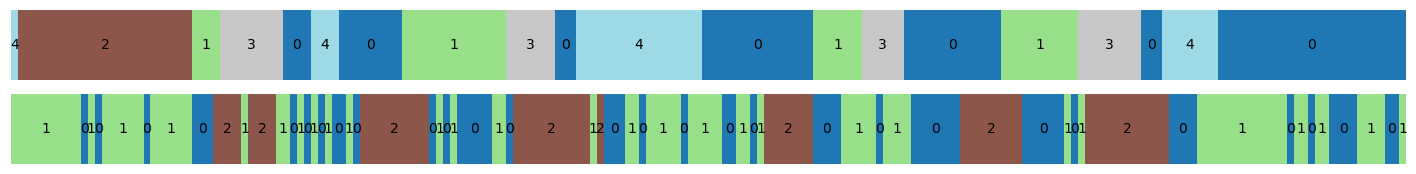

In [208]:
from rl.rl_util import tag_lunar_lander_phases_batch_2
buffer_phase = tag_lunar_lander_phases_batch_2(buffer_state, buffer_action, buffer_done)  # [L,]
n_phase = buffer_phase.max()+1
print(n_phase)
print("HMM labels shape:", hmm_labels.shape, hmm_post.shape, len(hmm_lengths) )
print(hmm_lengths)
fig, ax = plt.subplots(2,1, figsize=(18,2))
si = 0
ei = 200
hmm_label_present = hmm_labels[si:ei]
buffer_phase_present = buffer_phase[si:ei]
ax[0].imshow(hmm_labels[np.newaxis, si:ei], aspect='auto', cmap='tab20', vmin=0, vmax=n_components-1)
ax[1].imshow(buffer_phase[np.newaxis, si:ei], aspect='auto', cmap='tab20', vmin=0, vmax=n_components-1)
# print(hmm_labels[si:ei])
print(buffer_phase[si:ei])
boundaries = np.where(np.diff(hmm_label_present))[0]+1
phase_boundaries = np.where(np.diff(buffer_phase_present))[0]+1
# print(boundaries)
print(phase_boundaries)
zero_plus_boundaries = np.concatenate(([0], boundaries, [ei-si]))
zero_plus_phase_boundaries = np.concatenate(([0], phase_boundaries, [ei-si]))
# print(zero_plus_boundaries)
print(zero_plus_phase_boundaries)
centers = (zero_plus_boundaries[:-1] + zero_plus_boundaries[1:]) / 2 - 0.5
phase_centers = (zero_plus_phase_boundaries[:-1] + zero_plus_phase_boundaries[1:]) / 2 - 0.5
for i, c in enumerate(centers):
    ax[0].text(c, 0, hmm_label_present[zero_plus_boundaries[i]], color='k', ha='center', va='center')
for i, c in enumerate(phase_centers):
    ax[1].text(c, 0, buffer_phase_present[zero_plus_phase_boundaries[i]], color='k', ha='center', va='center')
ax[0].axis('off')
ax[1].axis('off')
# ax[0].set_xlim(0, ei - si)
# ax[1].set_xlim(0, ei - si)
path = f'./rl/output/lunarlander/simple_{simple_type}_ei_{ei_type}/critic_{critic_lr}_actor_{actor_lr}/{configuration}_hmm_phase_comparison_{network_name}.png'
os.makedirs(os.path.dirname(path), exist_ok=True)
plt.savefig(path, dpi=400)
print(path)

In [209]:
## split train and test and calculate the score
zero_plus_boundaries = np.cumsum(hmm_lengths)
train_indices = []
test_indices = []
start = 0
for i, end in enumerate(zero_plus_boundaries):
    L = end - start
    if i % 5 == 0:
        test_indices.append((start, end))   
    else:
        train_indices.append((start, end))
    start = end
print('Train episodes:', len(train_indices), 'Test episodes:', len(test_indices))
# Calculate train and test score
train_buffer_hidden = np.concatenate([buffer_hidden[s:e] for s,e in train_indices], axis=0)
test_buffer_hidden = np.concatenate([buffer_hidden[s:e] for s,e in test_indices], axis=0)
train_buffer_done = np.concatenate([buffer_done[s:e] for s,e in train_indices], axis=0)
test_buffer_done = np.concatenate([buffer_done[s:e] for s,e in test_indices], axis=0)

# Fit on train
train_labels, train_post, train_model_hmm, train_scaler, train_lengths = fit_hmm_gaussian(
    train_buffer_hidden,
    train_buffer_done,
    n_components=n_components,   # or n_components depending on your function signature
    cov_type="full",
    n_iter=200,
    seed=0
)

# Prepare features
X_train = train_scaler.transform(train_buffer_hidden)
X_test  = train_scaler.transform(test_buffer_hidden)

# Length lists
test_lengths = [e - s for s, e in test_indices]

# Sum log-likelihoods (hmmlearn default)
train_ll_sum = train_model_hmm.score(X_train, lengths=train_lengths)
test_ll_sum, test_posterior = train_model_hmm.score_samples(X_test,  lengths=test_lengths)

# Convert to average per timestep
train_T = int(np.sum(train_lengths))
test_T  = int(np.sum(test_lengths))

train_ll_avg = train_ll_sum / train_T
test_ll_avg  = test_ll_sum / test_T
print('HMM')
print(f"Train loglik per-step: {train_ll_avg:.6f} (T={train_T})")
print(f"Test  loglik per-step: {test_ll_avg:.6f} (T={test_T})")
f = open('./rl/hmm_metric.txt', 'a+')
f.write(configuration+' '+network_name+'\n')
f.write('HMM Train ll: '+str(train_ll_avg)+'\n')
f.write('HMM Test ll: '+str(test_ll_avg)+'\n')
train_labels_hmm = train_labels
test_labels_hmm = train_model_hmm.predict(X_test, lengths=test_lengths)


Train episodes: 16 Test episodes: 4
HMM
Train loglik per-step: 162.792587 (T=7963)
Test  loglik per-step: 156.288134 (T=2000)


In [210]:
train_confidence = train_post.max(1).mean()
test_confidence = test_posterior.max(1).mean()
print('HMM')
print('Train confidence:', train_confidence)
print('Test confidence:', test_confidence)
f.write('HMM Train confidence: '+str(train_confidence)+'\n')
f.write('HMM Test confidence: '+str(test_confidence)+'\n')
train_switch_rate = np.where(np.diff(train_labels_hmm),1,0).mean()
test_switch_rate = np.where(np.diff(test_labels_hmm),1,0).mean()
print('Train switch rate:', train_switch_rate)
print('Test switch rate:', test_switch_rate)
f.write('HMM Train switch rate: '+str(train_switch_rate)+'\n')
f.write('HMM Test switch rate: '+str(test_switch_rate)+'\n')

HMM
Train confidence: 0.9985480360507807
Test confidence: 0.9950424196118353
Train switch rate: 0.13941220798794274
Test switch rate: 0.14107053526763383


42

(2000, 5)


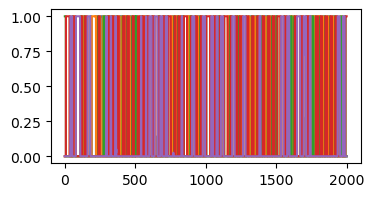

In [211]:
print(test_posterior.shape)
fig, ax = plt.subplots(1,1,figsize=(4,2))
for i in range(test_posterior.shape[1]):
    ax.plot(test_posterior[:,i])
plt.show()

In [212]:
from rl.rl_fitting import GMM
gmm = GMM().fit_one_K(X_train, n_components, seed=0)
train_ll_avg_gmm = gmm.score(X_train)
test_ll_avg_gmm = gmm.score(X_test)

print('GMM')
print(f"Train loglik per-step: {train_ll_avg_gmm:.6f} (T={train_T})")
print(f"Test  loglik per-step: {test_ll_avg_gmm:.6f} (T={test_T})")
train_labels_gmm = gmm.predict(X_train)
test_labels_gmm = gmm.predict(X_test)


GMM
Train loglik per-step: 162.755965 (T=7963)
Test  loglik per-step: 156.272832 (T=2000)


./rl/output/lunarlander/simple_rnn_ei_eisep/critic_0.005_actor_0.001/eisep_all_hmm_transition_matrix_actor.png


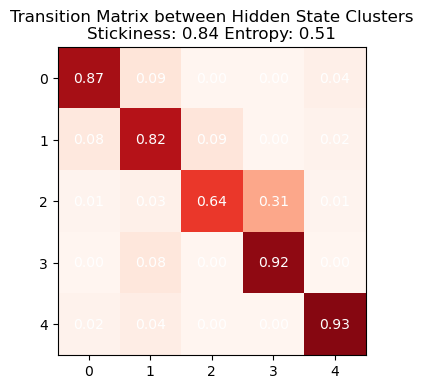

In [213]:
def transition_measure(transition):
    stickiness = np.trace(transition)/transition.shape[0]
    entropy = -np.mean((transition * np.log(transition+1e-6))) * transition.shape[1]
    return stickiness, entropy

GMM_transition = GMM().transition_matrix(train_labels_gmm)
HMM_transition = train_model_hmm.transmat_    # shape [K, K]

fig, ax = plt.subplots(1,1,figsize=(5,4))
transitions = [GMM_transition, HMM_transition]
names = ['GMM', 'HMM']
# for k in range(2):

#     transition = transitions[k]
#     ax[k].imshow(transition, cmap='Reds', vmin=0, vmax=1)
#     ax[k].set_xticks(np.arange(transition.shape[0]))
#     ax[k].set_yticks(np.arange(transition.shape[0]))

#     stickiness_single, off_diagonal_entropy = transition_measure(transition)
#     ax[k].set_title(f'{names[k]}\nStickiness: {stickiness_single:.2f} Entropy: {off_diagonal_entropy:.2f}')
#     for i in range(transition.shape[0]):
#         for j in range(transition.shape[1]):
#             text = ax[k].text(j, i, f'{transition[i, j]:.2f}',
#                         ha="center", va="center", color="w")


transition = HMM_transition
ax.imshow(transition, cmap='Reds', vmin=0, vmax=1)
ax.set_xticks(np.arange(transition.shape[0]))
ax.set_yticks(np.arange(transition.shape[0]))
stickiness_single, off_diagonal_entropy = transition_measure(transition)
ax.set_title(f'Transition Matrix between Hidden State Clusters\nStickiness: {stickiness_single:.2f} Entropy: {off_diagonal_entropy:.2f}')
for i in range(transition.shape[0]):
    for j in range(transition.shape[1]):
        text = ax.text(j, i, f'{transition[i, j]:.2f}',
                    ha="center", va="center", color="w")
# fig.suptitle('Transition Matrix between Hidden State Clusters')
# plt.show()
# f.write('HMM T stickiness: '+str(stickiness_single)+'\n')
# f.write('HMM T entropy: '+str(off_diagonal_entropy)+'\n')
path = f'./rl/output/lunarlander/simple_{simple_type}_ei_{ei_type}/critic_{critic_lr}_actor_{actor_lr}/{configuration}_hmm_transition_matrix_{network_name}.png'
os.makedirs(os.path.dirname(path), exist_ok=True)
plt.savefig(path, dpi=400)
print(path)

labels shape: (2000,)
labels shape: (2000,)
labels shape: (2000,)


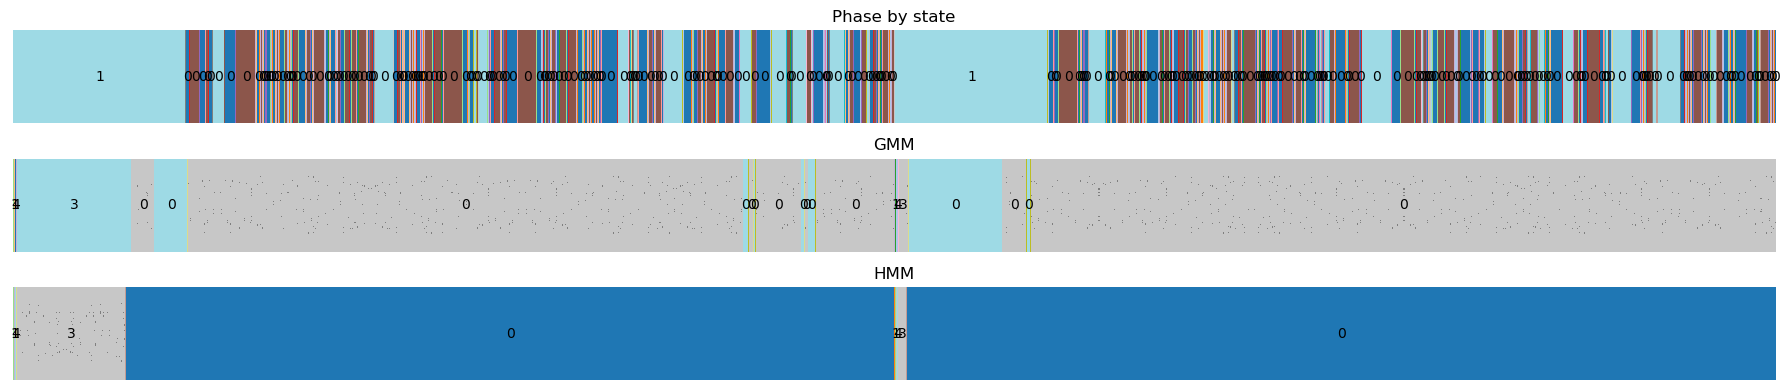

In [162]:
from rl.rl_util import tag_lunar_lander_phases_batch_2
train_state = np.concatenate([buffer_state[s:e] for s,e in train_indices], axis=0)
test_state = np.concatenate([buffer_state[s:e] for s,e in test_indices], axis=0)
train_action = np.concatenate([buffer_action[s:e] for s,e in train_indices], axis=0)
test_action = np.concatenate([buffer_action[s:e] for s,e in test_indices], axis=0)
train_phase = np.concatenate([buffer_phase[s:e] for s,e in train_indices], axis=0)
test_phase = np.concatenate([buffer_phase[s:e] for s,e in test_indices], axis=0)

n_phase = buffer_phase.max()+1
all_labels = [test_phase, test_labels_gmm, test_labels_hmm]
n_labels = [n_phase, n_components, n_components]
names = ['Phase by state', 'GMM', 'HMM']
fig, ax = plt.subplots(3,1, figsize=(18,4))
si = 0
ei = 1000
for i, label in enumerate(all_labels):
    print("labels shape:", label.shape)
    ax[i].imshow(label[None, si:ei], aspect='auto', cmap='tab20', vmin=0, vmax=n_labels[i]-1)
    boundaries = np.where(np.diff(label[si:ei]))[0]+1
    zero_plus_boundaries = np.concatenate(([si], boundaries, [ei]))
    centers = (zero_plus_boundaries[:-1] + zero_plus_boundaries[1:]) / 2
    for j, c in enumerate(centers):
        ax[i].text(c, 0, hmm_labels[zero_plus_boundaries[j]], color='k', ha='center', va='center')
    ax[i].axis('off')
    ax[i].set_title(names[i])
plt.tight_layout()
plt.show()
# print("HMM labels shape:", test_labels.shape, hmm_post.shape, len(hmm_lengths) )
# print(hmm_lengths)

# ax[0].imshow(hmm_labels[np.newaxis, si:ei], aspect='auto', cmap='tab20', vmin=0, vmax=n_components-1)
# ax[1].imshow(buffer_phase[np.newaxis, si:ei], aspect='auto', cmap='tab20', vmin=0, vmax=n_phase-1)
# print(hmm_labels[si:ei])
# print(buffer_phase[si:ei])
# boundaries = np.where(np.diff(hmm_labels[si:ei]))[0]+1
# phase_boundaries = np.where(np.diff(buffer_phase[si:ei]))[0]+1
# print(boundaries)
# zero_plus_boundaries = np.concatenate(([si], boundaries, [ei]))
# zero_plus_phase_boundaries = np.concatenate(([si], phase_boundaries, [ei]))
# print(zero_plus_boundaries)
# centers = (zero_plus_boundaries[:-1] + zero_plus_boundaries[1:]) / 2
# phase_centers = (zero_plus_phase_boundaries[:-1] + zero_plus_phase_boundaries[1:]) / 2
# for i, c in enumerate(centers):
#     ax[0].text(c, 0, hmm_labels[zero_plus_boundaries[i]], color='k', ha='center', va='center')
# for i, c in enumerate(phase_centers):
#     ax[1].text(c, 0, buffer_phase[zero_plus_phase_boundaries[i]], color='k', ha='center', va='center')
# ax[0].axis('off')
# ax[1].axis('off')

In [163]:
def mutual_information(label_1, label_2, eps=1e-12, normalized=True):
    """
    phase: [T] int (0..P-1)
    state: [T] int (0..K-1)
    Returns:
        MI (nats), and optionally NMI (0..1)
    """
    label_1 = np.asarray(label_1).astype(int).ravel()
    label_2 = np.asarray(label_2).astype(int).ravel()
    assert label_1.shape == label_2.shape

    P = label_1.max() + 1
    K = label_2.max() + 1

    # joint counts
    joint = np.zeros((P, K), dtype=np.float64)
    np.add.at(joint, (label_1, label_2), 1.0)

    T = joint.sum()
    p_ps = joint / (T + eps)
    p_p  = p_ps.sum(axis=1, keepdims=True)  # [P,1]
    p_s  = p_ps.sum(axis=0, keepdims=True)  # [1,K]

    # MI = sum p_ps * log(p_ps/(p_p p_s))
    ratio = (p_ps + eps) / (p_p * p_s + eps)
    mi = np.sum(p_ps * np.log(ratio))

    if not normalized:
        return mi

    Hp = -np.sum(p_p * np.log(p_p + eps))
    Hs = -np.sum(p_s * np.log(p_s + eps))
    nmi = mi / (np.sqrt(Hp * Hs) + eps)
    return mi, nmi
mi, nmi = mutual_information(train_phase, train_labels_hmm)
print('Train MI:', mi, 'NMI:', nmi)
f.write('Train NMI: '+str(nmi)+'\n')
mi, nmi = mutual_information(test_phase, test_labels_hmm)
print('Test MI:', mi, 'NMI:', nmi)
f.write('Test NMI: '+str(nmi)+'\n')
from sklearn.metrics import adjusted_mutual_info_score
ami = adjusted_mutual_info_score(train_phase, train_labels_hmm)
print('Train AMI:', ami)
ami = adjusted_mutual_info_score(test_phase, test_labels_hmm)
print('Test AMI:', ami)
f.close()

Train MI: 0.012559640144742808 NMI: 0.015592821223189156
Test MI: 0.010744982156789692 NMI: 0.015569874520488454
Train AMI: 0.014308859715249856
Test AMI: 0.011792654124793188


In [164]:

from matplotlib.animation import FuncAnimation, FFMpegWriter

buffer_reward = buffer.reward[:buffer.ptr]
buffer_frame = buffer.frame[:buffer.ptr]/255  # [L, 40, 60, 3]



si = 0
ei = 500
frames = buffer_frame[si:ei]
phases = buffer_phase[si:ei]
rewards = buffer_reward[si:ei]
states = buffer_state[si:ei]
dones = buffer_done[si:ei]
actions = buffer_action[si:ei]
labels = hmm_labels[si:ei]
print(phases)
phase_names = ['Free fall', 'Braking', 'Horizontal align', 'Touchdown prep', 'Landed', 'Crash']
action_names = ['Nothing', 'Left Engine', 'Main Engine', 'Right Engine']
L = len(frames)

fig, ax = plt.subplots(figsize=(8,8))
im = ax.imshow(frames[0])
ax.axis("off")

def update(i):
    im.set_array(frames[i])
    ax.set_title(f"Frame {i}, Phase:{phase_names[phases[i]]}, Action:{action_names[int(actions[i].item())]}, HMMLabel:{labels[i]}\n"\
                 f"x:{states[i,0]:.2f}, y:{states[i,1]:.2f}, vx:{states[i,2]:.2f}, vy:{states[i,3]:.2f}\n"\
                 f"a:{states[i,4]:.2f}, va:{states[i,5]:.2f}, LC:{states[i,6]:.0f}, RC:{states[i,7]:.0f}\n"\
                f"reward:{float(rewards[i]):.2f}, done:{int(dones[i])}", fontsize=16)
    return [im]

ani = FuncAnimation(fig, update, frames=L, interval=33)

writer = FFMpegWriter(fps=10)
ani.save("./rl/video_from_buffer.mp4", writer=writer)

plt.close(fig)
print("Saved ./rl/video_from_buffer.mp4")


AttributeError: 'RL_Hidden_Buffer' object has no attribute 'frame'

In [ ]:

def save_frame_to_video(frames, states, actions, phases, rewards, dones, labels, filename):
    from matplotlib.animation import FuncAnimation, FFMpegWriter

    phase_names = ['Free fall', 'Braking', 'Horizontal align', 'Touchdown prep', 'Landed', 'Crash']
    action_names = ['Nothing', 'Left Engine', 'Main Engine', 'Right Engine']
    L = len(frames)

    fig, ax = plt.subplots(figsize=(8,8))
    im = ax.imshow(frames[0])
    ax.axis("off")
    if not os.path.exists(os.path.dirname(filename)):
        os.makedirs(os.path.dirname(filename))
    def update(i):
        im.set_array(frames[i])
        ax.set_title(f"Frame {i}, Phase:{phase_names[phases[i]]}, Action:{action_names[int(actions[i].item())]}, HMMLabel:{labels[i]}\n"\
                     f"x:{states[i,0]:.2f}, y:{states[i,1]:.2f}, vx:{states[i,2]:.2f}, vy:{states[i,3]:.2f}\n"\
                     f"a:{states[i,4]:.2f}, va:{states[i,5]:.2f}, LC:{states[i,6]:.0f}, RC:{states[i,7]:.0f}\n"\
                    f"reward:{float(rewards[i]):.2f}, done:{int(dones[i])}", fontsize=16)
        return [im]

    ani = FuncAnimation(fig, update, frames=L, interval=33)

    writer = FFMpegWriter(fps=10)
    ani.save(filename, writer=writer)

    plt.close(fig)
    print(f"Saved {filename}")

In [ ]:
### collect clips for different labels
n_label = n_components
clips = dict()
boundaries = np.where(np.diff(hmm_labels))[0]+1
for i, boundary in enumerate(boundaries):
    start = boundaries[i-1] if i > 0 else 0
    end = boundary
    label = hmm_labels[start]

    if label not in clips:
        clips[label] = []
    if end-start >= 3:
        # clip = buffer_frame[start:end]/255
        clips[label].append({'start': start, 'end': end})
        # print('start:', start, 'end:', end, 'label:', label)

for label in clips:
    print(f'Label {label}: {len(clips[label])} clips')
    # Save clips as mp4
    for i, clip in enumerate(clips[label]):
        if i > 10:
            break
        start = clip['start']
        end = clip['end']
    
        frames = buffer_frame[start:end]
        # print('frames:', frames)
        phases = buffer_phase[start:end]
        rewards = buffer_reward[start:end]
        states = buffer_state[start:end]
        dones = buffer_done[start:end]
        actions = buffer_action[start:end]
        labels = hmm_labels[start:end]
        save_frame_to_video(frames, states, actions, phases, rewards, dones, labels,
                            filename=f'./rl/video/label_{label}/clip_{i}.mp4')